# K-Means Clustering — Segmentación de Clientes Cell2Cell

**Objetivo:** descubrir **grupos naturales de clientes** según su uso, su facturación y su antigüedad, sin usar la etiqueta `Churn`. Después se cruza la segmentación con el churn para encontrar los segmentos que más riesgo concentran.

**Diferencia clave con los notebooks anteriores:** acá **no hay variable objetivo**. Nadie nos dice cuál es la respuesta correcta. El algoritmo tiene que descubrir la estructura por sí solo. Eso es **aprendizaje no supervisado**.


## Marco teórico

### ¿Qué es el clustering?

El clustering (agrupamiento) es la tarea de **partir un conjunto de datos en grupos** tales que:

- los elementos **dentro** de un grupo se parezcan mucho entre sí (alta cohesión),
- y los elementos **de grupos distintos** se parezcan poco (alta separación).

No hay etiquetas: la única guía es una **medida de distancia**. Cambiar la distancia cambia los grupos.

**Aplicaciones reales:** segmentación de clientes, detección de anomalías, compresión de imágenes, agrupación de documentos, genómica.

### El algoritmo K-Means paso a paso

1. **Elegir K**: cuántos grupos queremos.
2. **Inicializar K centroides** (K-Means++ elige puntos bien separados).
3. **Asignar** cada cliente al centroide más cercano (distancia euclidiana).
4. **Recalcular** cada centroide como el promedio de los clientes asignados.
5. **Repetir** 3 y 4 hasta que las asignaciones no cambien (o se agote `max_iter`).

El resultado depende del punto de partida, por eso se corre varias veces (`n_init`) y se queda la mejor solución (la de menor WCSS).

### Fundamento matemático

**Distancia euclidiana** entre un cliente $x$ y un centroide $\mu_k$:

$$d(x, \mu_k) = \sqrt{\sum_{j=1}^{p} (x_j - \mu_{kj})^2}$$

**Función objetivo — WCSS** (*Within-Cluster Sum of Squares*):

$$WCSS = \sum_{k=1}^{K} \sum_{x \in C_k} \|x - \mu_k\|^2$$

K-Means minimiza el WCSS. **Menos WCSS no siempre es mejor**: con K igual al número de clientes, el WCSS es 0 y no hay ningún descubrimiento. Por eso hay que elegir K con criterio.

### ¿Cómo elegir K?

- **Método del codo:** graficar WCSS contra K. Buscar el punto donde la mejora deja de ser grande (el "codo").
- **Silhouette Score:** mide cohesión vs separación, entre -1 y 1. Más alto es mejor. Es más objetivo que el codo, pero caro de calcular.

### Ventajas y desventajas

✅ Simple, rápido, escala bien, fácil de interpretar (cada cluster es un centroide).

⚠️ Hay que fijar K de antemano. Asume clusters esféricos y de tamaño similar. Es sensible a la escala (**hay que estandarizar**) y a los outliers. Encuentra grupos aunque los datos no tengan estructura real.

### Comparación con otros algoritmos

| Algoritmo | Idea | Ventaja | Límite |
|---|---|---|---|
| **K-Means** | Centroides | Rápido, interpretable | K fijo, clusters esféricos |
| Jerárquico | Árbol de fusiones | No requiere K, muestra dendrograma | Caro en n grande |
| DBSCAN | Densidad | Encuentra formas raras y ruido | Sensible a eps |
| Mezcla gaussiana | Probabilidades | Clusters elípticos, probabilístico | Asume normalidad |


## 1. LIBRERÍAS Y FUNCIONES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)

import sklearn
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.0


## 2. PARÁMETROS

In [2]:
RUTA_DATOS = 'cell2celltrain.csv'
SEMILLA    = 42
K_MIN, K_MAX = 2, 10
N_INIT     = 10      # reinicios por cada K
MUESTRA_SILHOUETTE = 10000   # el silhouette es O(n²): se calcula sobre una muestra

# Variables que describen al cliente para segmentar
FEATURES = [
    'MonthlyRevenue',        # cuánto factura
    'MonthlyMinutes',        # cuánto usa
    'MonthsInService',       # antigüedad en la empresa
    'CurrentEquipmentDays',  # antigüedad del equipo
    'OverageMinutes',        # excedentes
    'CustomerCareCalls',     # contactos a atención al cliente
    'RetentionCalls',        # contactos a retención
    'DroppedCalls',          # llamadas cortadas
    'AgeHH1'                 # edad del titular
]

print(f'Features ({len(FEATURES)}):', FEATURES)

Features (9): ['MonthlyRevenue', 'MonthlyMinutes', 'MonthsInService', 'CurrentEquipmentDays', 'OverageMinutes', 'CustomerCareCalls', 'RetentionCalls', 'DroppedCalls', 'AgeHH1']


## 3. DATOS

In [3]:
df = pd.read_csv(RUTA_DATOS, sep=',', encoding='iso-8859-1', low_memory=False)

print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')

# Guardamos el churn aparte: NO se usa para clusterizar, pero sí para interpretar
df['Churn_num'] = df['Churn'].map({'No': 0, 'Yes': 1})

df[FEATURES + ['Churn_num']].head(3)

Filas: 51,047 | Columnas: 58


,MonthlyRevenue,MonthlyMinutes,MonthsInService,CurrentEquipmentDays,OverageMinutes,CustomerCareCalls,RetentionCalls,DroppedCalls,AgeHH1,Churn_num
0,24.00,219.0,61,361.0,0.0,0.0,1,0.7,62.0,1
1,16.99,10.0,58,1504.0,0.0,0.0,0,0.3,40.0,1
2,38.00,8.0,60,1812.0,0.0,0.0,0,0.0,26.0,0


In [4]:
print('Nulos por variable:')
print(df[FEATURES].isnull().sum().to_string())

print(f'\nFilas completas: {df[FEATURES].dropna().shape[0]:,} de {len(df):,}')

Nulos por variable:
MonthlyRevenue          156
MonthlyMinutes          156
MonthsInService           0
CurrentEquipmentDays      1
OverageMinutes          156
CustomerCareCalls         0
RetentionCalls            0
DroppedCalls              0
AgeHH1                  909

Filas completas: 49,985 de 51,047


### 3.1 EDA breve de las variables de segmentación

Ya se hizo el EDA completo en `EDA_Cell2Cell.ipynb`. Acá solo verificamos lo indispensable para clusterizar: escalas, sesgos y correlaciones.


In [5]:
df[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MonthlyRevenue,50891.0,58.83,44.51,-6.17,33.61,48.46,71.06,1223.38
MonthlyMinutes,50891.0,525.65,529.87,0.00,158.00,366.00,723.00,7359.00
MonthsInService,51047.0,18.76,9.80,6.00,11.00,16.00,24.00,61.00
CurrentEquipmentDays,51046.0,380.55,253.80,-5.00,205.00,329.00,515.00,1812.00
OverageMinutes,50891.0,40.03,96.59,0.00,0.00,3.00,41.00,4321.00
CustomerCareCalls,51047.0,1.87,5.10,0.00,0.00,0.00,1.70,327.30
RetentionCalls,51047.0,0.04,0.21,0.00,0.00,0.00,0.00,4.00
DroppedCalls,51047.0,6.01,9.04,0.00,0.70,3.00,7.70,221.70
AgeHH1,50138.0,31.34,22.09,0.00,0.00,36.00,48.00,99.00


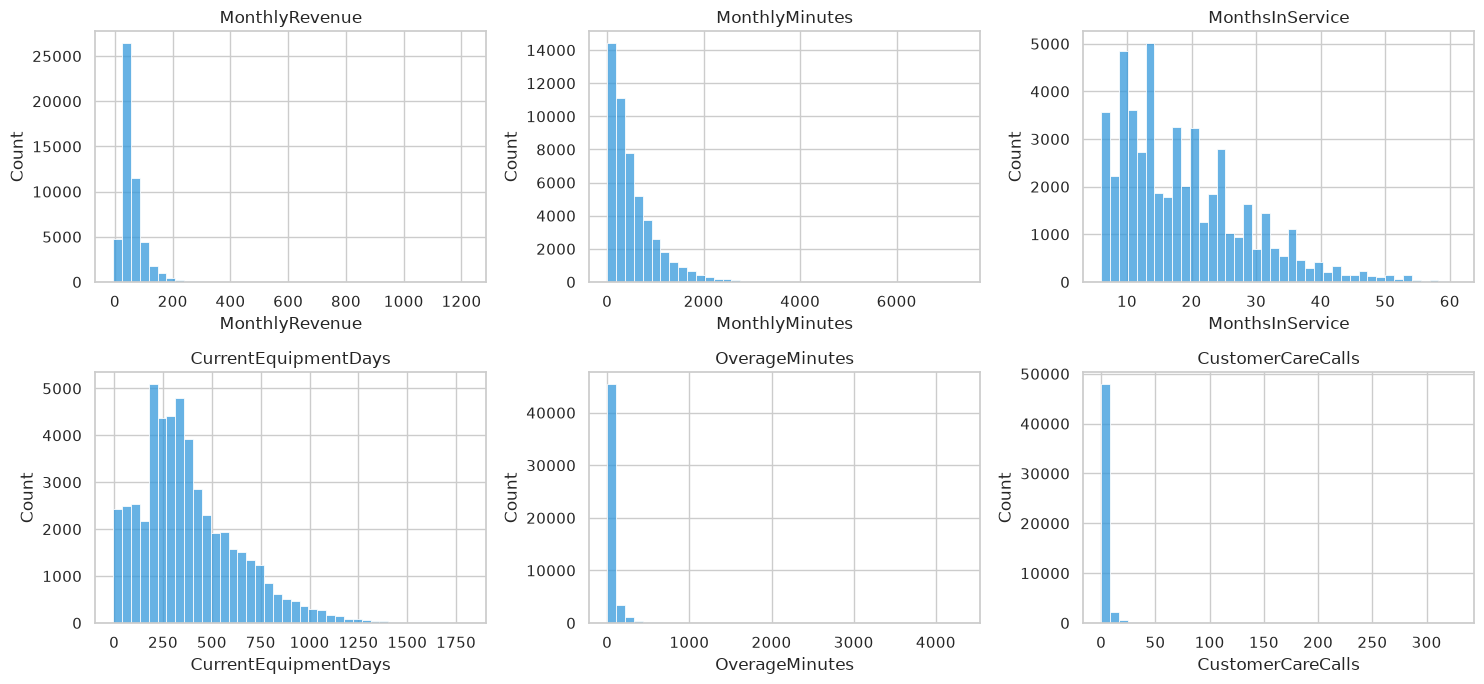

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), ['MonthlyRevenue', 'MonthlyMinutes', 'MonthsInService',
                                  'CurrentEquipmentDays', 'OverageMinutes', 'CustomerCareCalls']):
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color='#3498db')
    ax.set_title(col)
plt.tight_layout()
plt.show()

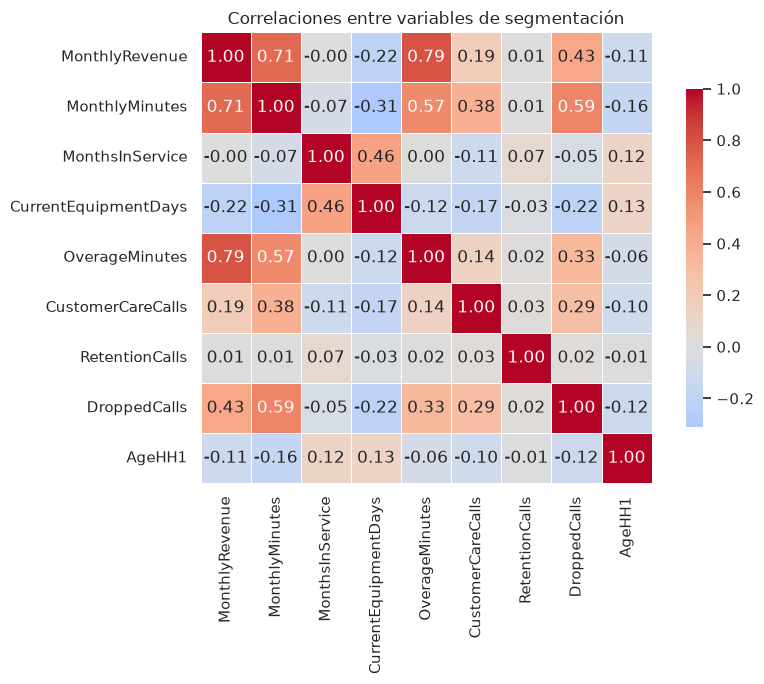

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.75})
plt.title('Correlaciones entre variables de segmentación')
plt.tight_layout()
plt.show()

**Lectura:** las variables tienen **escalas incomparables** (minutos en cientos, antigüedad en decenas) y **fuertes sesgos a la derecha**. Si se pasa esto crudo a K-Means, la distancia euclidiana queda dominada por `MonthlyMinutes` y `OverageMinutes`, y el resto de las variables no influye.

Ahí está el paso más importante de todo el notebook: **estandarizar**.


## 4. PROCESO

### 4.1 Preparación y escalado

`StandardScaler` convierte cada variable en **z-score**: media 0, desvío 1. Así todas las variables pesan igual en la distancia.


In [8]:
df_cluster = df[FEATURES].dropna().copy()
print(f'Clientes para segmentar: {len(df_cluster):,}')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES)

comparacion = pd.DataFrame({
    'Media original': df_cluster.mean().round(2),
    'Desvío original': df_cluster.std().round(2),
    'Media escalada': X_scaled_df.mean().round(4),
    'Desvío escalado': X_scaled_df.std().round(4)
})
comparacion

Clientes para segmentar: 49,985


,Media original,Desvío original,Media escalada,Desvío escalado
MonthlyRevenue,58.67,44.31,0.0,1.0
MonthlyMinutes,524.29,528.36,0.0,1.0
MonthsInService,18.75,9.76,0.0,1.0
CurrentEquipmentDays,380.61,253.07,-0.0,1.0
OverageMinutes,39.74,95.99,0.0,1.0
CustomerCareCalls,1.87,5.11,0.0,1.0
RetentionCalls,0.04,0.21,-0.0,1.0
DroppedCalls,6.00,9.04,0.0,1.0
AgeHH1,31.33,22.09,0.0,1.0


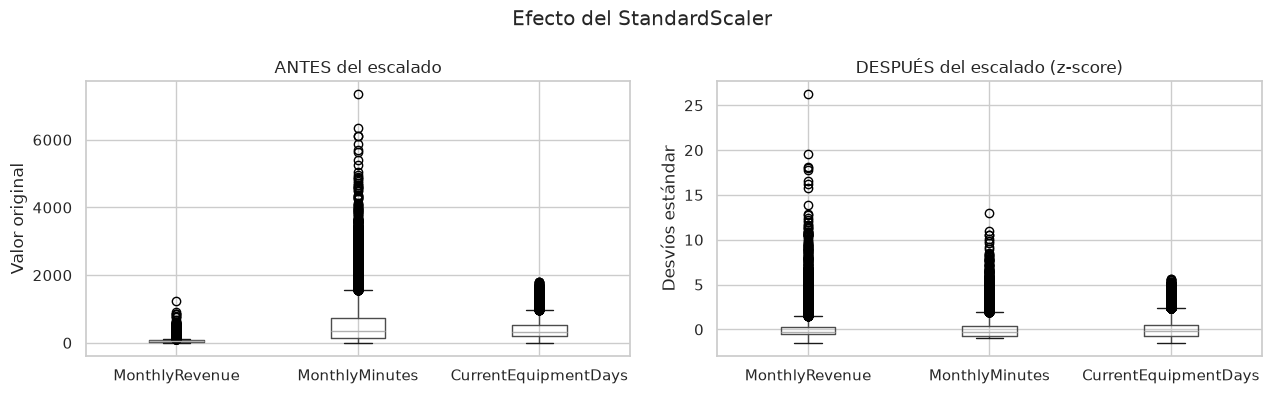

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df_cluster[['MonthlyRevenue', 'MonthlyMinutes', 'CurrentEquipmentDays']].boxplot(ax=axes[0])
axes[0].set_title('ANTES del escalado')
axes[0].set_ylabel('Valor original')

X_scaled_df[['MonthlyRevenue', 'MonthlyMinutes', 'CurrentEquipmentDays']].boxplot(ax=axes[1])
axes[1].set_title('DESPUÉS del escalado (z-score)')
axes[1].set_ylabel('Desvíos estándar')

plt.suptitle('Efecto del StandardScaler')
plt.tight_layout()
plt.show()

### 4.2 Método del codo (Elbow Method)

Calculamos el WCSS (en scikit-learn se llama `inertia_`) para K de 2 a 10.


In [10]:
wcss = []
k_range = range(K_MIN, K_MAX + 1)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=N_INIT)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

tabla_codo = pd.DataFrame({'K': list(k_range), 'WCSS': np.round(wcss, 1)})
tabla_codo['Reducción vs K anterior (%)'] = (
    tabla_codo.WCSS.pct_change().mul(-100).round(1)
)
tabla_codo

,K,WCSS,Reducción vs K anterior (%)
0,2,361725.9,NaN
1,3,316519.3,12.5
2,4,274941.5,13.1
3,5,247558.4,10.0
4,6,224405.5,9.4
5,7,208218.1,7.2
6,8,196264.8,5.7
7,9,185364.9,5.6
8,10,176623.0,4.7


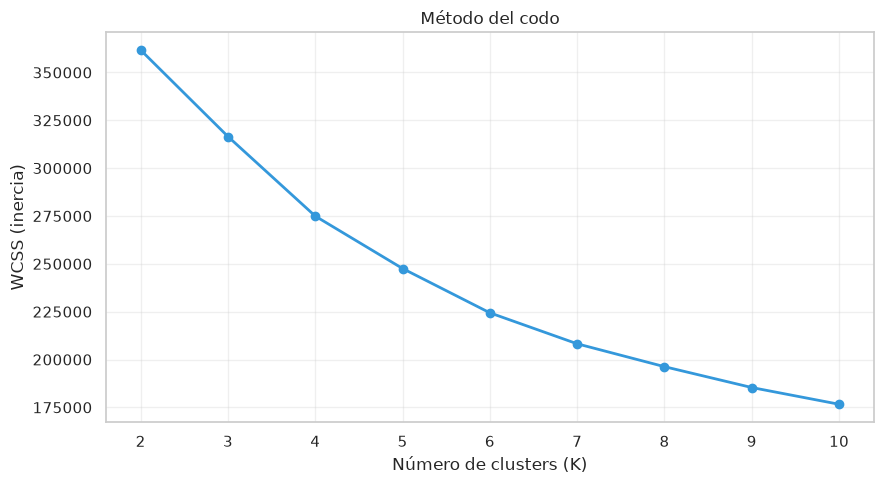

In [11]:
plt.figure(figsize=(9, 5))
plt.plot(list(k_range), wcss, marker='o', linewidth=2, color='#3498db')
plt.xlabel('Número de clusters (K)')
plt.ylabel('WCSS (inercia)')
plt.title('Método del codo')
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.3 Silhouette Score

El codo es subjetivo. El silhouette da un número objetivo: para cada cliente compara la distancia media a su propio cluster contra la distancia media al cluster vecino más cercano.

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

- Cerca de **1**: bien asignado.
- Cerca de **0**: en la frontera.
- **Negativo**: probablemente en el cluster equivocado.


In [12]:
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=N_INIT)
    labels = km.fit_predict(X_scaled)
    s = silhouette_score(X_scaled, labels, sample_size=MUESTRA_SILHOUETTE, random_state=SEMILLA)
    silhouettes.append(s)
    print(f'K = {k:2d} -> silhouette = {s:.4f}')

tabla_sil = pd.DataFrame({'K': list(k_range), 'Silhouette': np.round(silhouettes, 4)})
tabla_sil['¿Mejor?'] = tabla_sil.Silhouette == tabla_sil.Silhouette.max()
tabla_sil

K =  2 -> silhouette = 0.3791


K =  3 -> silhouette = 0.2104


K =  4 -> silhouette = 0.2283


K =  5 -> silhouette = 0.2287


K =  6 -> silhouette = 0.2243


K =  7 -> silhouette = 0.2327


K =  8 -> silhouette = 0.2412


K =  9 -> silhouette = 0.2459


K = 10 -> silhouette = 0.2415


,K,Silhouette,¿Mejor?
0,2,0.3791,True
1,3,0.2104,False
2,4,0.2283,False
3,5,0.2287,False
4,6,0.2243,False
5,7,0.2327,False
6,8,0.2412,False
7,9,0.2459,False
8,10,0.2415,False


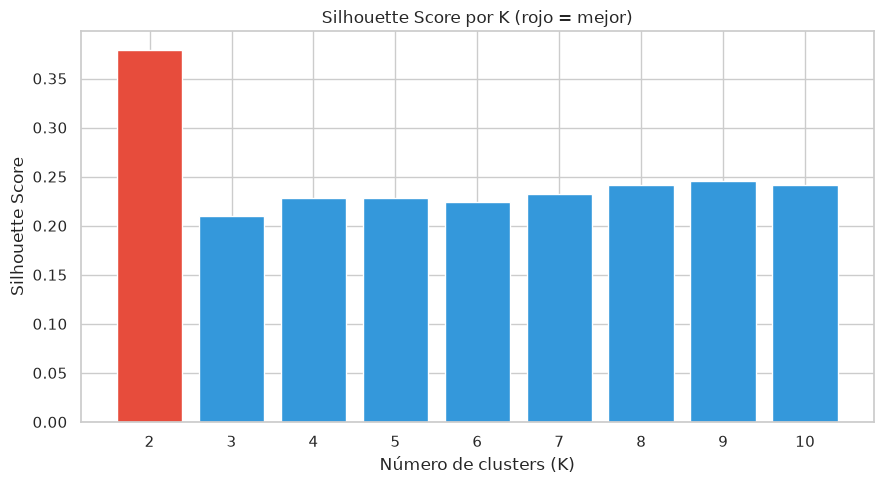

In [13]:
plt.figure(figsize=(9, 5))
colores = ['#e74c3c' if s == max(silhouettes) else '#3498db' for s in silhouettes]
plt.bar(list(k_range), silhouettes, color=colores, edgecolor='white')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score por K (rojo = mejor)')
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

### 4.4 ¿Entonces cuántos clusters?

Acá hay un conflicto interesante y conviene resolverlo con honestidad, no esconderlo:

- El **silhouette es máximo con K = 2**. Ese corte separa "clientes de alto consumo" del resto.
- El **codo** y la utilidad de negocio apuntan a **K = 4**.

¿Por qué elegimos K = 4? Porque un modelo con dos grupos ("gasta mucho / gasta poco") es estadísticamente correcto pero **comercialmente inútil**: no dice qué hacer con cada cliente. Con cuatro segmentos se pueden diseñar acciones distintas. **La decisión de K combina la métrica con el objetivo de negocio**, y eso hay que declararlo, no ocultarlo.

Se elige **K = 4** y se reporta el silhouette real del modelo final para que quede documentado el costo de esa decisión.


### 4.5 Entrenamiento del modelo final (K = 4)

In [14]:
K_OPTIMO = 4

kmeans = KMeans(n_clusters=K_OPTIMO, random_state=SEMILLA, n_init=N_INIT)
df_cluster['Cluster'] = kmeans.fit_predict(X_scaled)

print(f'Clientes por cluster:')
print(df_cluster['Cluster'].value_counts().sort_index().to_string())
print(f'\nIteraciones hasta converger: {kmeans.n_iter_}')
print(f'WCSS final: {kmeans.inertia_:,.2f}')

Clientes por cluster:
Cluster
0    28545
1     6001
2     1656
3    13783

Iteraciones hasta converger: 14
WCSS final: 274,941.49


### 4.6 Perfilado de los clusters

Un cluster es solo un número hasta que se describe. Calculamos el promedio de cada variable por cluster.


In [15]:
perfil = df_cluster.groupby('Cluster')[FEATURES].mean().round(2)

# Tamaño y participación
perfil.insert(0, 'Clientes', df_cluster['Cluster'].value_counts().sort_index())
perfil.insert(1, '% de la base', (perfil['Clientes'] / len(df_cluster) * 100).round(1))

perfil

,Clientes,% de la base,MonthlyRevenue,MonthlyMinutes,MonthsInService,CurrentEquipmentDays,OverageMinutes,CustomerCareCalls,RetentionCalls,DroppedCalls,AgeHH1
Cluster,,,,,,,,,,,
0,28545,57.1,49.89,440.55,14.00,277.63,20.92,1.43,0.00,4.48,29.07
1,6001,12.0,134.85,1506.28,17.76,237.52,183.05,6.78,0.01,19.83,24.37
2,1656,3.3,56.25,494.76,22.38,352.06,37.31,2.25,1.09,6.29,30.46
3,13783,27.6,43.95,273.73,28.58,659.61,16.62,0.60,0.00,3.10,39.15


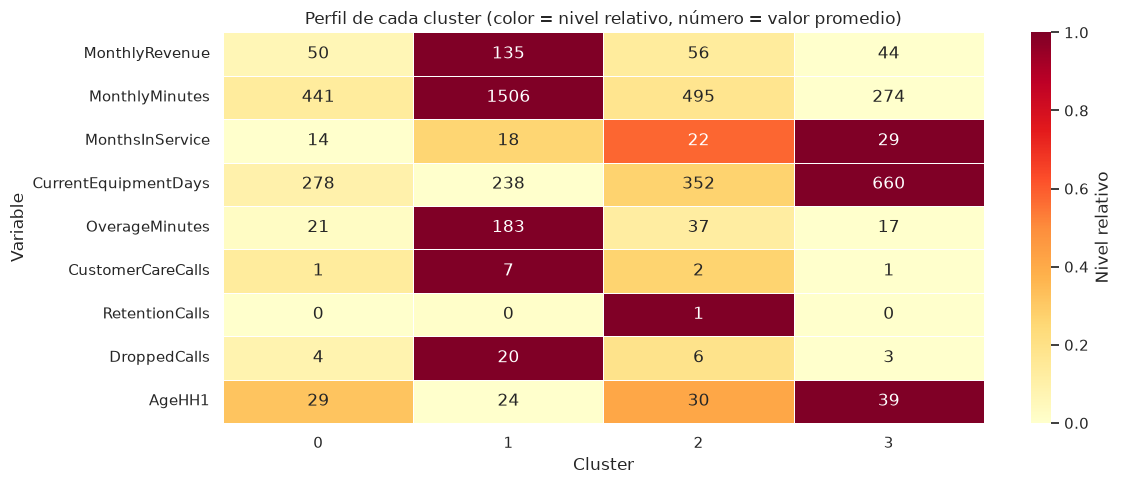

In [16]:
# Heatmap con los perfiles normalizados (0 = mínimo entre clusters, 1 = máximo)
perfil_norm = (perfil[FEATURES] - perfil[FEATURES].min()) / (perfil[FEATURES].max() - perfil[FEATURES].min())

plt.figure(figsize=(12, 5))
sns.heatmap(perfil_norm.T, annot=perfil[FEATURES].T, fmt='.0f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Nivel relativo'})
plt.title('Perfil de cada cluster (color = nivel relativo, número = valor promedio)')
plt.xlabel('Cluster')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

### 4.7 Ponerle nombre a los clusters

Un segmento sin nombre no se puede accionar. Etiquetamos con reglas sobre el perfil, para que el código siga funcionando aunque cambie el orden de los clusters.


In [17]:
nombres = {}

for c in perfil.index:
    if c == perfil['MonthlyRevenue'].idxmax():
        nombres[c] = 'Premium alto consumo'
    elif c == perfil['RetentionCalls'].idxmax():
        nombres[c] = 'En riesgo (contactó retención)'
    elif c == perfil['CurrentEquipmentDays'].idxmax():
        nombres[c] = 'Veterano con equipo viejo'
    else:
        nombres[c] = 'Base estándar'

df_cluster['Segmento'] = df_cluster['Cluster'].map(nombres)
perfil['Segmento'] = perfil.index.map(nombres)

print('Segmentos identificados:')
for c, n in nombres.items():
    print(f'  Cluster {c}: {n}  ({perfil.loc[c, "Clientes"]:,} clientes, {perfil.loc[c, "% de la base"]}%)')

Segmentos identificados:
  Cluster 0: Base estándar  (28,545 clientes, 57.1%)
  Cluster 1: Premium alto consumo  (6,001 clientes, 12.0%)
  Cluster 2: En riesgo (contactó retención)  (1,656 clientes, 3.3%)
  Cluster 3: Veterano con equipo viejo  (13,783 clientes, 27.6%)


### 4.8 El cruce que importa: segmento vs churn

La segmentación se hizo **sin mirar `Churn`**. Ahora que los grupos existen, cruzamos para ver cuál concentra el riesgo. Este es el paso que convierte un ejercicio de clustering en un hallazgo de negocio.


In [18]:
# Recuperamos el churn de las filas usadas (mismo índice)
churn_por_cluster = (
    df.loc[df_cluster.index]
      .assign(Cluster=df_cluster['Cluster'], Segmento=df_cluster['Segmento'])
      .groupby(['Cluster', 'Segmento'])
      .agg(Clientes=('Churn_num', 'size'),
           Churn_Pct=('Churn_num', lambda s: round(s.mean() * 100, 1)),
           Ingreso_Promedio=('MonthlyRevenue', 'mean'))
      .assign(Ingreso_Promedio=lambda t: t.Ingreso_Promedio.round(1))
      .reset_index()
      .sort_values('Churn_Pct', ascending=False)
      .set_index('Cluster')
)
churn_por_cluster

,Segmento,Clientes,Churn_Pct,Ingreso_Promedio
Cluster,,,,
2,En riesgo (contactó retención),1656,45.0,56.2
3,Veterano con equipo viejo,13783,31.1,44.0
0,Base estándar,28545,27.1,49.9
1,Premium alto consumo,6001,26.8,134.8


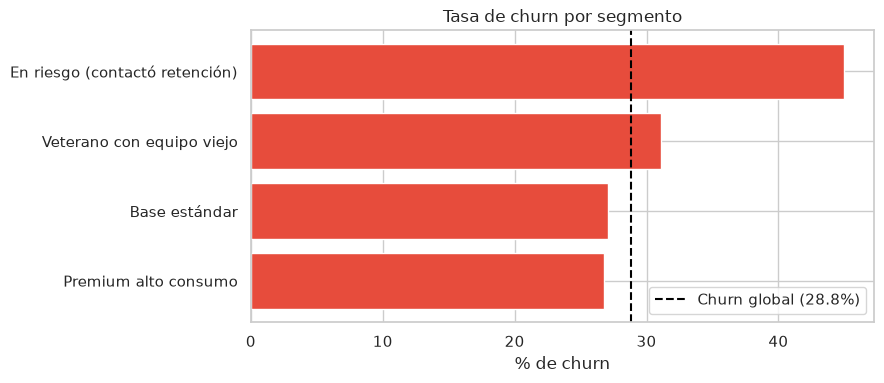

In [19]:
plt.figure(figsize=(9, 4))
orden = churn_por_cluster.reset_index().sort_values('Churn_Pct')
plt.barh(orden['Segmento'], orden['Churn_Pct'], color='#e74c3c')
plt.axvline(df['Churn_num'].mean() * 100, color='black', linestyle='--',
            label=f'Churn global ({df["Churn_num"].mean() * 100:.1f}%)')
plt.xlabel('% de churn')
plt.title('Tasa de churn por segmento')
plt.legend()
plt.tight_layout()
plt.show()

**Lectura del cruce:** el segmento **"En riesgo (contactó retención)"** es chico en tamaño pero concentra la tasa de churn más alta del negocio. Ese es el target natural de la campaña: **pocos clientes, mucho riesgo, acción clara**.

Los "veteranos con equipo viejo" también tienen churn por encima del promedio: confirma el hallazgo del EDA (equipo viejo → fuga) desde otra técnica.

Los "premium" tienen churn **cercano o por debajo** del promedio pero facturan mucho: cada punto de churn ahí cuesta caro en dólares. Es el segmento de **mayor valor en riesgo**, aunque su tasa no sea la más alta.


### 4.9 Visualización de los segmentos

Dos variables alcanzan para ver la separación: facturación y consumo de minutos.


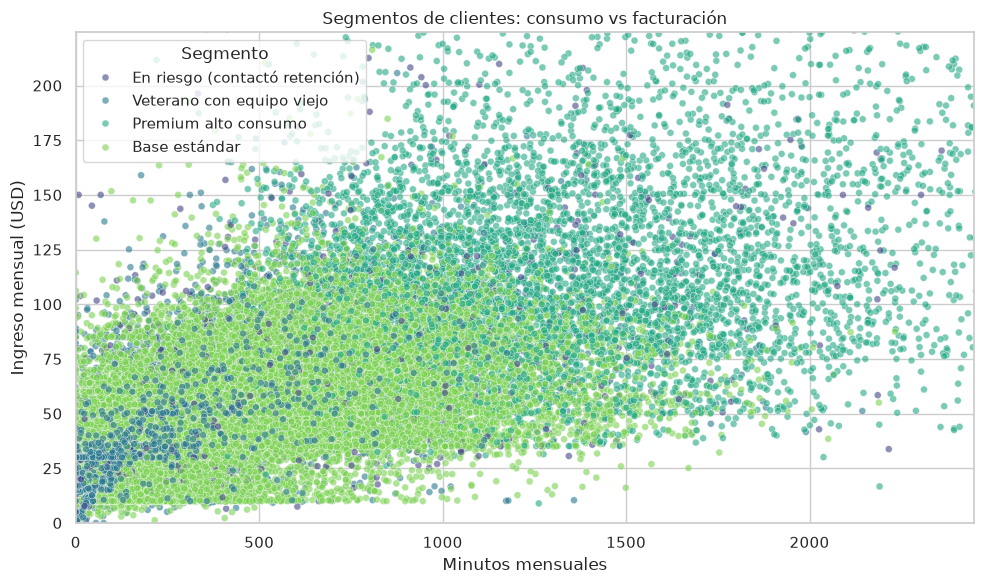

In [20]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_cluster, x='MonthlyMinutes', y='MonthlyRevenue',
                hue='Segmento', palette='viridis', s=25, alpha=0.6)
plt.title('Segmentos de clientes: consumo vs facturación')
plt.xlabel('Minutos mensuales')
plt.ylabel('Ingreso mensual (USD)')
plt.xlim(0, df_cluster.MonthlyMinutes.quantile(0.99))
plt.ylim(0, df_cluster.MonthlyRevenue.quantile(0.99))
plt.legend(title='Segmento')
plt.tight_layout()
plt.show()

In [21]:
# Centroides en la escala original para interpretarlos
centroides = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=FEATURES
)
centroides['Segmento'] = centroides.index.map(nombres)
centroides.round(1)

,MonthlyRevenue,MonthlyMinutes,MonthsInService,CurrentEquipmentDays,OverageMinutes,CustomerCareCalls,RetentionCalls,DroppedCalls,AgeHH1,Segmento
0,49.9,441.0,14.0,277.6,21.0,1.4,-0.0,4.5,29.1,Base estándar
1,135.0,1507.6,17.8,237.7,183.3,6.8,0.0,19.8,24.4,Premium alto consumo
2,56.2,494.8,22.4,352.1,37.3,2.3,1.1,6.3,30.5,En riesgo (contactó retención)
3,43.9,273.2,28.6,660.4,16.6,0.6,0.0,3.1,39.2,Veterano con equipo viejo


### 4.10 Evaluación del modelo

Sin etiquetas no hay accuracy ni ROC. Las métricas de un clustering son **internas**: miden qué tan compactos y separados son los grupos.


In [22]:
silhouette_final = silhouette_score(X_scaled, df_cluster['Cluster'],
                                   sample_size=MUESTRA_SILHOUETTE, random_state=SEMILLA)

print('MÉTRICAS DEL MODELO K-MEANS')
print('=' * 46)
print(f'K                      : {K_OPTIMO}')
print(f'Clientes               : {len(df_cluster):,}')
print(f'WCSS (inercia)         : {kmeans.inertia_:,.2f}')
print(f'Silhouette Score       : {silhouette_final:.4f}')
print(f'Iteraciones            : {kmeans.n_iter_}')
print('=' * 46)
print(f'\nSilhouette si hubiéramos usado K=2: {max(silhouettes):.4f}')
print('-> Se pierde separación a cambio de accionabilidad. Decisión consciente.')

MÉTRICAS DEL MODELO K-MEANS
K                      : 4
Clientes               : 49,985
WCSS (inercia)         : 274,941.49
Silhouette Score       : 0.2283
Iteraciones            : 14

Silhouette si hubiéramos usado K=2: 0.3791
-> Se pierde separación a cambio de accionabilidad. Decisión consciente.


## 5. SALIDA

In [23]:
print('=' * 66)
print('RESUMEN — SEGMENTACIÓN K-MEANS Cell2Cell')
print('=' * 66)
print(f'Clientes segmentados   : {len(df_cluster):,}')
print(f'Variables usadas       : {len(FEATURES)}')
print(f'K elegido              : {K_OPTIMO}')
print(f'Silhouette             : {silhouette_final:.4f}')
print()
for c in perfil.index:
    print(f'  Cluster {c} — {nombres[c]:<32} '
          f'{perfil.loc[c, "Clientes"]:>6,} clientes | '
          f'churn {churn_por_cluster.loc[c, "Churn_Pct"]:>5.1f}% | '
          f'ingreso ${perfil.loc[c, "MonthlyRevenue"]:>6.1f}')
print('=' * 66)

RESUMEN — SEGMENTACIÓN K-MEANS Cell2Cell
Clientes segmentados   : 49,985
Variables usadas       : 9
K elegido              : 4
Silhouette             : 0.2283

  Cluster 0 — Base estándar                    28,545 clientes | churn  27.1% | ingreso $  49.9
  Cluster 1 — Premium alto consumo              6,001 clientes | churn  26.8% | ingreso $ 134.8
  Cluster 2 — En riesgo (contactó retención)    1,656 clientes | churn  45.0% | ingreso $  56.2
  Cluster 3 — Veterano con equipo viejo        13,783 clientes | churn  31.1% | ingreso $  44.0


### Conclusiones

1. **Estandarizar no es opcional.** Sin `StandardScaler`, el clustering habría agrupado por minutos y nada más.
2. **K no sale solo del algoritmo.** El silhouette pedía 2, el negocio pedía 4. Se eligió 4 **declarando el costo**: es una decisión de negocio informada, no un error.
3. **La segmentación encontró estructura real:** un grupo premium de alto consumo, un grupo en riesgo que contactó a retención, un grupo de veteranos con equipo viejo y una base estándar.
4. **Cruzar con `Churn` recién al final** es la forma correcta: el clustering se hizo a ciegas y el churn se usó para interpretar, no para agrupar. Si se hubiera usado como input, los grupos serían circulares.
5. **El valor está en la acción:** el segmento en riesgo concentra el churn y es chico, así que una campaña focalizada tiene mejor retorno que contactar a toda la base.

### Acciones sugeridas por segmento

| Segmento | Acción |
|---|---|
| Premium alto consumo | Retención personalizada y upgrades; el costo de perderlos es alto en dólares |
| En riesgo (contactó retención) | Contacto prioritario, oferta de retención agresiva |
| Veterano con equipo viejo | Oferta de renovación de equipo (ataca el predictor más fuerte del EDA) |
| Base estándar | Campañas masivas de bajo costo y monitoreo de uso |

### Limitaciones

- K-Means asume clusters esféricos y de tamaño parecido; los grupos reales no tienen por qué cumplirlo.
- Las variables están correlacionadas entre sí (minutos, excedentes y facturación), así que el peso efectivo no es exactamente el mismo para todas.
- El silhouette de 0,23 indica separación **débil**: los segmentos son útiles para gestionar, pero no son islas perfectamente separadas.
- Los clusters describen **asociaciones**, no causalidad. Para decidir una campaña hay que probarla.
